# Libraries

In [ ]:
! pip install kaggle emoji langdetect pillow wordcloud pyldavis flair --quiet
! pip install numpy gensim --upgrade --quiet


# restart the runtime after executing this cell
# colab shortcut: Ctrl + M + .

In [ ]:
! mkdir ~/.kaggle
! cp kaggle.json ~/.kaggle/
! chmod 600 ~/.kaggle/kaggle.json

In [ ]:
import re
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

import emoji
import langdetect
from wordcloud import WordCloud
from pprint import pprint

import gensim
import gensim.corpora as corpora
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
import pyLDAvis
import pyLDAvis.gensim_models

import nltk
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

from sklearn.metrics import accuracy_score, classification_report

import flair

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('vader_lexicon', quiet=True)

True


# Functions

In [ ]:
#  func to detect tweet language

def detect_lang(txt):
    """
    Input: Text
    Output: Text language

    """
    try:
        return langdetect.detect(txt)
    except:
        return 'n.d' # not detected

# func to give statistic about data frame

def lang_stat(df):
    """
    Input: Data frame
    Output: Statistical summary about the data frame language

    """

    print(f"Number of Languages:{len(df['lang'].unique())}\n")
    print(f"List of Languages:\n{df['lang'].unique()}\n")
    print(f"Total Number of Tweets: {len(df['tweet'])}\n")
    print(f"Number of Tweets in English: {len(df[df['lang'] == 'en'])}\n")
    print(f"Number of Tweets in languages other than english: {len(df[df['lang'] != 'en'])}\n")

    fig, ax = plt.subplots(figsize=(16,12))
    sns.histplot(data=df, x='lang', ax=ax)

# func to remove emojis

def rem_emoji(txt):
    """
    Input: Text
    Output: Emoji-free text

    """

    return emoji.replace_emoji(txt, '')

# func to remove links

def rem_link(txt):
    """
    Input: Text
    Output: Link-free text
    
    """

    txt = re.sub(r'http\S+', '', txt)
    txt = re.sub(r'bit.ly/\S+', '', txt)
    txt = txt.strip('[link]')
    txt = re.sub(r'pic.twitter\S+','', txt)
    return txt

# func to remove user and retweet tags

def rem_user(txt):
    """
    Input: Text
    Output: Text without username or retweet tag
    
    """

    txt = re.sub('(RT\s@[A-Za-z]+[A-Za-z0-9-_]+)', '', txt)
    txt = re.sub('(@[A-Za-z]+[A-Za-z0-9-_]+)', '', txt)
    return txt

# func to remove hashtags

def rem_hashtag(txt):
    """
    Input: Text
    Output: Hashtag-free text
    
    """

    txt = re.sub('(#[A-Za-z]+[A-Za-z0-9-_]+)', '', txt)
    return txt

# func to remove video and audio 

def rem_va(txt):
    """
    Input: Text
    Output: Text without video and audio tags
    
    """

    txt = re.sub('VIDEO:', '', txt)
    txt = re.sub('AUDIO:', '', txt)
    return txt

# func to return tokenized representation of words in lemma form
# and exclude stop words

stopwords = [s for s in gensim.parsing.preprocessing.STOPWORDS]

def tokenize(txt):
    """
    Input: Text
    Output: Tokenized and lemantized text without stopwords
    
    """

    return \
    [WordNetLemmatizer().lemmatize(token, pos='v') 
    for token in gensim.utils.simple_preprocess(txt) 
    if token not in stopwords and len(token) > 2]

# func to do all the preprocessing steps on tweet

def pp_tweet(txt):
    """
    Input: Text
    Output: Do all the preprocessing steps on text and return tokenized sentence
    
    """

    punctuation = '!”$%&\’()*+,-./:;<=>?[\\]^_`{|}~•@'
    txt = rem_emoji(txt)
    txt = rem_link(txt)
    txt = rem_user(txt)
    txt = rem_hashtag(txt)
    txt = rem_va(txt)
    txt = txt.lower()
    txt = re.sub('[' + punctuation + ']+', ' ', txt)
    txt = re.sub('\s+', ' ', txt)
    txt = re.sub('([0-9]+)', '', txt)
    txt_token_list = tokenize(txt)
    txt = ' '.join(txt_token_list)
    return txt

# func to generate word cloud

def gen_wordcloud(df):
    """
    Input: Dataframe
    Output: Word cloud
    
    """

    text = ' '.join(t for t in df['tk_tweet'])

    word_cloud = WordCloud(width=4000, 
                        height=3000, 
                        random_state=2022, 
                        collocations=False).generate(text)

    plt.figure(figsize=(16,12))
    plt.imshow(word_cloud)
    plt.axis("off")
    plt.show()

# func to do all three topic modeling algorithms (LSI, NMF, LDA)

def topic_modeling(df, topic_num):
    """
    Input: Data frame, topic number
    Output: Returns gensim topic modeling objects including dictionary, corpus, 
            LSI, NMF , and LDA models with their coherence score
    
    """

    texts = [t.split() for t in df['tk_tweet']]

    dictionary = Dictionary(texts)

    dictionary.filter_extremes(no_below=5, no_above=0.5, keep_n=20000)

    corpus = [dictionary.doc2bow(t) for t in texts]

    # corpus_lsi = [id2word.doc2bow(t) for t in texts]

    # LSI
    
    model_lsi = gensim.models.lsimodel.LsiModel(corpus=corpus,
                                                id2word=dictionary,
                                                num_topics=topic_num,
                                                random_seed=2022,
                                                chunksize=250)
    
    coherence_model_lsi = CoherenceModel(model=model_lsi, 
                                         texts=texts, 
                                         dictionary=dictionary, 
                                         coherence='c_v')
    
    coh_lsi = coherence_model_lsi.get_coherence()
    
    # NMF

    tfidf = gensim.models.TfidfModel(dictionary=dictionary)

    corpus_tfidf = list(tfidf[corpus])

    model_nmf = gensim.models.Nmf(corpus=corpus_tfidf, 
                                  num_topics=topic_num, 
                                  id2word=dictionary, 
                                  chunksize=250, 
                                  passes=5, 
                                  eval_every=10,  
                                  minimum_probability=0, 
                                  random_state=2022, 
                                  kappa=1)
    
    coherence_model_nmf = CoherenceModel(model=model_nmf, 
                                         texts=texts, 
                                         dictionary=dictionary, 
                                         coherence='c_v')
    
    coh_nmf = coherence_model_nmf.get_coherence()
    
    # LDA

    model_lda = gensim.models.ldamodel.LdaModel(corpus=corpus, 
                                                id2word=dictionary, 
                                                num_topics=topic_num, 
                                                random_state=2022,
                                                chunksize=250)
    
    coherence_model_lda = CoherenceModel(model=model_lda, 
                                         texts=texts, 
                                         dictionary=dictionary, 
                                         coherence='c_v')
    
    coh_lda = coherence_model_lda.get_coherence()
    
    
    return dictionary, corpus, model_lsi, model_nmf, model_lda, coh_lsi, coh_nmf, coh_lda

# func to calculate the topic modeling accuracy

def get_tm_acc(df, label):
    """
    Input: Data frame, predicted labeles
    Output: accuracy of the model
    
    """
    a = list(sum([df['label'] == label])).count(1)
    b = df.shape[0]
    return a/b

# func to get the NMF labels 
# assign class 0 to 0 and class 1 to label 1

def get_nmf_label_12(text):
    """
    Input: Text
    Output: NMF most probable topic
    
    """
    topic_prob = nmf.get_document_topics(dictionary.doc2bow(text))
    if len(topic_prob) == 2:
        if topic_prob[0][1] > topic_prob[1][1]:
            return topic_prob[0][0]
        else:
            return topic_prob[1][0]
    if len(topic_prob) == 1:
        if topic_prob[0][0] == 0:
            return 0
        if topic_prob[0][0] == 1:
            return 1

# func to get the NMF labels 
# assign class 0 to label 1 and class 1 to label 0

def get_nmf_label_21(text):
    """
    Input: Text
    Output: NMF most probable topic
    
    """
    topic_prob = nmf.get_document_topics(dictionary.doc2bow(text))
    if len(topic_prob) == 2:
        if topic_prob[0][1] > topic_prob[1][1]:
            return topic_prob[0][0]
        else:
            return topic_prob[1][0]
    if len(topic_prob) == 1:
        if topic_prob[0][0] == 0:
            return 1
        if topic_prob[0][0] == 1:
            return 0
    
# func to find the best labeling strategy and set those labels on dataset

def set_nmf_label(df):
    """
    Input: Data frame
    Output: Data frame with NMF labels
    
    """

    label_12 = pd.Series([get_nmf_label_12(t.split()) for t in df['tk_tweet']])
    acc_12 = get_tm_acc(df, label_12)

    label_21 = pd.Series([get_nmf_label_21(t.split()) for t in df['tk_tweet']])
    acc_21 = get_tm_acc(df, label_21)

    if acc_12 > acc_21:
        return label_12
    else:
        return label_21

# func to get the LDA labels 
# assign class 0 to 0 zero and class 1 to label 1

def get_lda_label_12(text):
    """
    Input: Text
    Output: LDA most probable topic
    
    """
    topic_prob = lda.get_document_topics(dictionary.doc2bow(text))
    if topic_prob[0][1] > topic_prob[1][1]:
        return topic_prob[0][0]
    else:
        return topic_prob[1][0]

# func to get the LDA labels 
# assign class 0 to label 1 and class 1 to label 0

def get_lda_label_21(text):
    """
    Input: Text
    Output: NMF most probable topic
    
    """
    topic_prob = lda.get_document_topics(dictionary.doc2bow(text))
    if topic_prob[0][1] > topic_prob[1][1]:
        return topic_prob[1][0]
    else:
        return topic_prob[0][0]

# func to find the best labeling strategy and set those labels on dataset
    
def set_lda_label(df):
    """
    Input: Data frame
    Output: Data frame with LDA labels
    
    """

    label_12 = pd.Series([get_lda_label_12(t.split()) for t in df['tk_tweet']])
    acc_12 = get_tm_acc(df, label_12)

    label_21 = pd.Series([get_lda_label_21(t.split()) for t in df['tk_tweet']])
    acc_21 = get_tm_acc(df, label_21)

    if acc_12 > acc_21:
        return label_12
    else:
        return label_21

# func to do the sentiment analysis with flair library

sent = flair.models.TextClassifier.load('en-sentiment')

def flair_analyser(txt):
    """
    Input: Text
    Output: Flair polarity score
    
    """
    
    if len(txt) != 0:

        s = flair.data.Sentence(txt)

        sent.predict(s)

        if s.labels[0].to_dict()['value'] == 'POSITIVE':

            return int(1)
            
        if s.labels[0].to_dict()['value'] == 'NEGATIVE':

            return int(-1)

        else:

            return 0
            
    else:

        return None

# Qatar World Cup 2022

## EDA & Preprocessing

In [ ]:
! kaggle datasets download konradb/qatar-world-cup-2022-tweets
! unzip qatar-world-cup-2022-tweets.zip

In [ ]:
qatar_wc = pd.read_csv('tweets.csv')

In [ ]:
qatar_wc.head(5)

,user_name,user_location,user_description,user_created,user_followers,user_friends,user_favourites,user_verified,date,text,hashtags,source
0,Craig Forrest,NaN,@PremierLeague @WestHam @ChelseaFC @IpswichTow...,2011-01-14 19:09:55+00:00,20346.0,10591.0,18790.0,True,2023-01-18 15:49:26+00:00,Thanks Oso for sharing your experience at the ...,"['QatarWorldCup2022', 'TFCLive']",Twitter for iPhone
1,Hosayni Official,NaN,K Drama lover 😉🙂,2022-06-22 23:22:12+00:00,7.0,10.0,93.0,False,2023-01-18 15:33:42+00:00,1 month ago at #QatarWorldCup2022 #Davido 001 ...,"['QatarWorldCup2022', 'Davido']",Twitter for Android
2,꧁Jineesh Janardhanan꧂,Harippad (Alappuzha ),"The Patriarch, Megastar #Mammootty NadippinNay...",2019-08-25 10:32:09+00:00,2414.0,4961.0,15326.0,False,2023-01-18 14:18:42+00:00,It's been exactly a month 🏆\n#Argentina #Qatar...,"['Argentina', 'Qatar', 'QatarWorldCup2022', 'M...",Twitter for Android
3,iLOT,NaN,Sports betting & Lottery,2021-07-15 03:20:39+00:00,3201.0,111.0,421.0,False,2023-01-18 13:46:52+00:00,Exactly one month 🏆\n#QatarWorldCup2022 https:...,['QatarWorldCup2022'],TweetDeck
4,Chanda Dalmiya,"Kolkata, India",NaN,2020-03-07 10:50:09+00:00,397.0,3821.0,13600.0,False,2023-01-18 13:46:34+00:00,@a23_fantasy Answer :- D) 6 Times\n\n#ContestA...,"['ContestAlert', 'ChaloSaathKhelein', 'A23', '...",Twitter for Android


In [ ]:
qatar_wc.shape

(403947, 12)

In [ ]:
qatar_wc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403947 entries, 0 to 403946
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   user_name         403947 non-null  object 
 1   user_location     356390 non-null  object 
 2   user_description  387544 non-null  object 
 3   user_created      124668 non-null  object 
 4   user_followers    124668 non-null  float64
 5   user_friends      124668 non-null  object 
 6   user_favourites   124668 non-null  object 
 7   user_verified     124668 non-null  object 
 8   date              124666 non-null  object 
 9   text              124668 non-null  object 
 10  hashtags          94667 non-null   object 
 11  source            124658 non-null  object 
dtypes: float64(1), object(11)
memory usage: 37.0+ MB


In [ ]:
qatar_wc.isna().sum()

user_name                0
user_location        47557
user_description     16403
user_created        279279
user_followers      279279
user_friends        279279
user_favourites     279279
user_verified       279279
date                279281
text                279279
hashtags            309280
source              279289
dtype: int64

In [ ]:
# select only text column and remove null values

df_wc = pd.DataFrame(data = qatar_wc, columns = ['text'])
df_wc.dropna(inplace = True)
df_wc.reset_index(drop=True, inplace=True)
df_wc.rename(columns = {'text':'tweet'}, inplace = True)
df_wc.shape

(124668, 1)

In [ ]:
df_wc.head(3)

,tweet
0,Thanks Oso for sharing your experience at the ...
1,1 month ago at #QatarWorldCup2022 #Davido 001 ...
2,It's been exactly a month 🏆\n#Argentina #Qatar...


In [ ]:
df_wc['lang'] = df_wc['tweet'].apply(detect_lang)

Number of Languages:37

List of Languages:
['en' 'de' 'ca' 'id' 'es' 'ar' 'fr' 'so' 'it' 'sv' 'sl' 'tr' 'tl' 'et'
 'da' 'af' 'ro' 'pt' 'no' 'hr' 'n.d' 'pl' 'nl' 'cy' 'sq' 'fi' 'cs' 'hu'
 'th' 'vi' 'sw' 'sk' 'ur' 'lv' 'ml' 'lt' 'ja']

Total Number of Tweets: 124668

Number of Tweets in English: 120773

Number of Tweets in languages other than english: 3895



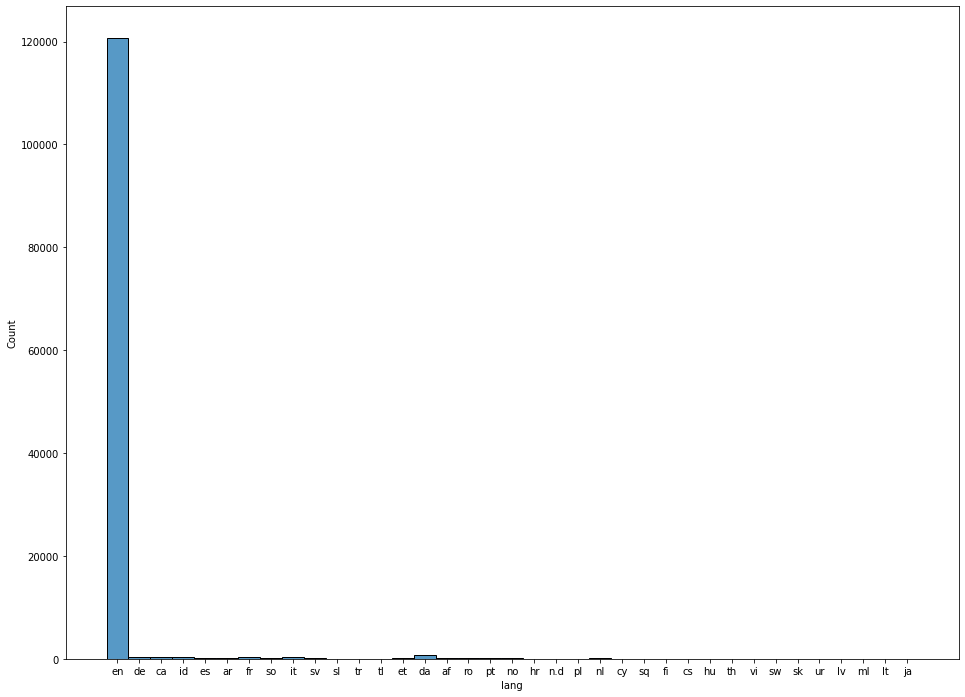

In [ ]:
# insight about the language people tweet in

lang_stat(df_wc)

In [ ]:
# df.to_csv('qatar_lang_tweets.csv')

In [ ]:
# remove tweets which are not in english

df_wc_en = df_wc[df_wc['lang'] == 'en']

# drop lang column cause we don't need it anymore

df_wc_en.drop(['lang'], axis=1, inplace=True)

/usr/local/lib/python3.8/dist-packages/pandas/core/frame.py:4906: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().drop(


In [ ]:
df_wc_en['tk_tweet'] = df_wc_en['tweet'].apply(pp_tweet)

<ipython-input-37-00c036973c1f>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_wc_en['tk_tweet'] = df_wc_en['tweet'].apply(pp_tweet)


In [ ]:
# df_en = pd.read_csv('qatar_en_tweet.csv')

In [ ]:
df_wc_en.head(3)

In [ ]:
# df_en.to_csv('qatar_en_tweet.csv')

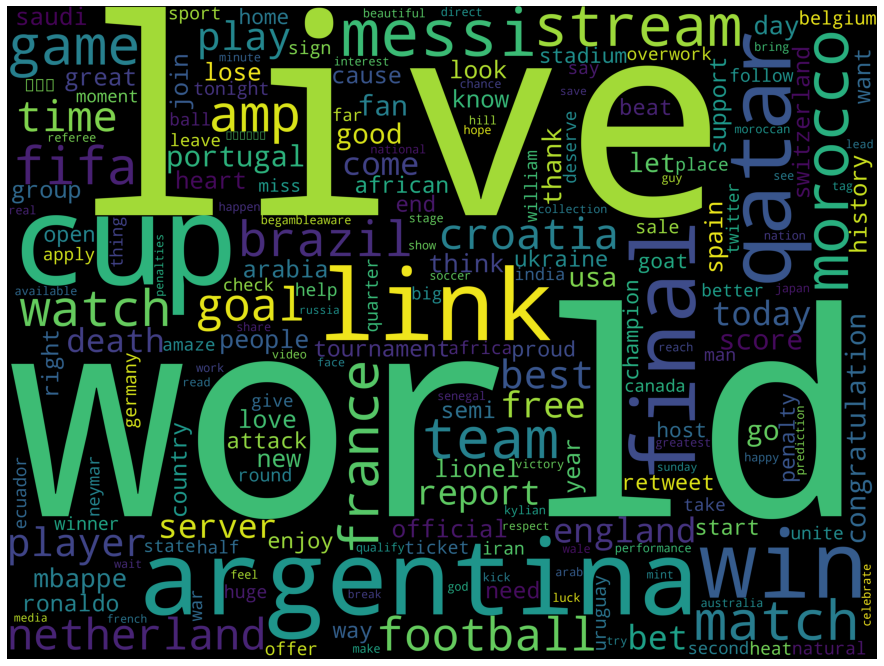

In [ ]:
gen_wordcloud(df_wc_en)

## Topic Modeling

In [ ]:
dictionary_wc, corpus_wc, lsi_wc, nmf_wc, lda_wc, \
coh_lsi_wc, coh_nmf_wc, coh_lda_wc = \
topic_modeling(df_wc_en, 5)

In [ ]:
pprint(lsi_wc.show_topics())

[(0,
  '0.734*"live" + 0.433*"link" + 0.252*"stream" + 0.211*"world" + 0.198*"cup" '
  '+ 0.192*"argentina" + 0.124*"netherlands" + 0.096*"watch" + 0.093*"brazil" '
  '+ 0.082*"fifa"'),
 (1,
  '0.621*"world" + 0.562*"cup" + -0.296*"live" + -0.171*"link" + 0.162*"qatar" '
  '+ 0.139*"fifa" + 0.129*"win" + 0.125*"messi" + 0.114*"final" + '
  '-0.084*"stream"'),
 (2,
  '0.488*"messi" + 0.409*"argentina" + 0.221*"win" + -0.208*"world" + '
  '0.206*"france" + -0.206*"cup" + 0.173*"amp" + 0.166*"bet" + 0.160*"free" + '
  '0.155*"mbappe"'),
 (3,
  '0.422*"free" + 0.396*"bet" + 0.238*"amp" + -0.208*"argentina" + '
  '0.191*"apply" + 0.191*"offer" + 0.190*"begambleaware" + 0.190*"sign" + '
  '0.190*"william" + 0.190*"hill"'),
 (4,
  '0.361*"help" + 0.348*"hack" + 0.341*"attempt" + 0.339*"assistance" + '
  '0.338*"device" + 0.314*"歌謡祭" + 0.314*"でストラジャ" + 0.307*"イコラブ" + '
  '0.306*"ジャニーズwest" + -0.071*"server"')]


In [ ]:
print('LSI Coherence: ', coh_lsi_wc)

LSI Coherence:  0.3670392621841682


In [ ]:
pprint(nmf_wc.show_topics())

[(0,
  '0.063*"report" + 0.058*"death" + 0.032*"official" + 0.032*"cause" + '
  '0.028*"overwork" + 0.028*"heat" + 0.028*"natural" + 0.028*"heart" + '
  '0.027*"attack" + 0.018*"india"'),
 (1,
  '0.112*"歌謡祭" + 0.112*"でストラジャ" + 0.111*"hack" + 0.110*"イコラブ" + '
  '0.110*"ジャニーズwest" + 0.109*"device" + 0.109*"assistance" + 0.106*"attempt" + '
  '0.100*"help" + 0.007*"late"'),
 (2,
  '0.168*"live" + 0.130*"link" + 0.073*"stream" + 0.049*"netherlands" + '
  '0.036*"brazil" + 0.032*"argentina" + 0.027*"watch" + 0.023*"server" + '
  '0.022*"switzerland" + 0.021*"free"'),
 (3,
  '0.035*"world" + 0.034*"cup" + 0.024*"win" + 0.020*"argentina" + '
  '0.017*"final" + 0.016*"france" + 0.015*"fifa" + 0.014*"messi" + '
  '0.014*"qatar" + 0.013*"morocco"'),
 (4,
  '0.081*"sale" + 0.072*"collection" + 0.071*"polygon" + 0.071*"verify" + '
  '0.071*"contract" + 0.060*"live" + 0.043*"pinky" + 0.043*"punks" + '
  '0.038*"pinkypunkss" + 0.036*"volume"')]


In [ ]:
print('NMF Coherence: ',coh_nmf_wc)

NMF Coherence:  0.45780793672881037


In [ ]:
pprint(lda_wc.show_topics())

[(0,
  '0.052*"amp" + 0.034*"go" + 0.026*"free" + 0.026*"enjoy" + 0.023*"brazil" + '
  '0.021*"home" + 0.019*"join" + 0.015*"point" + 0.013*"work" + 0.012*"india"'),
 (1,
  '0.119*"open" + 0.047*"ceremony" + 0.032*"goal" + 0.032*"right" + '
  '0.030*"nation" + 0.027*"valencia" + 0.026*"score" + 0.023*"jungkook" + '
  '0.017*"enner" + 0.015*"human"'),
 (2,
  '0.029*"host" + 0.018*"team" + 0.017*"football" + 0.013*"arabia" + '
  '0.012*"people" + 0.011*"start" + 0.011*"saudi" + 0.011*"good" + '
  '0.011*"country" + 0.011*"know"'),
 (3,
  '0.096*"qatar" + 0.083*"world" + 0.073*"cup" + 0.037*"match" + '
  '0.034*"ecuador" + 0.032*"game" + 0.031*"fifa" + 0.021*"win" + 0.020*"watch" '
  '+ 0.017*"lose"'),
 (4,
  '0.237*"live" + 0.128*"link" + 0.075*"stream" + 0.045*"watch" + 0.019*"buy" '
  '+ 0.018*"beer" + 0.018*"qatari" + 0.014*"broadcast" + 0.013*"server" + '
  '0.012*"try"')]


In [ ]:
print('LDA Coherence: ', coh_lda_wc)

LDA Coherence:  0.3077422375077807


In [ ]:
pyLDAvis.enable_notebook()

vis = pyLDAvis.gensim_models.prepare(lda_wc, 
                                     corpus_wc, 
                                     dictionary_wc, 
                                     mds='mmds',
                                     R=30)

vis

/usr/local/lib/python3.8/dist-packages/pyLDAvis/_prepare.py:246: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  default_term_info = default_term_info.sort_values(


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
3      0.403135 -0.007946       1        1  35.662256
2      0.166697  0.333756       2        1  29.663331
0     -0.351363 -0.206296       3        1  13.297202
4     -0.306432  0.285873       4        1  12.010024
1      0.087964 -0.405387       5        1   9.367188, topic_info=            Term          Freq         Total Category  logprob  loglift
979         live  26347.000000  26347.000000  Default  30.0000  30.0000
41         qatar  31989.000000  31989.000000  Default  29.0000  29.0000
318         link  14288.000000  14288.000000  Default  28.0000  28.0000
32         world  27383.000000  27383.000000  Default  27.0000  27.0000
48           cup  24246.000000  24246.000000  Default  26.0000  26.0000
...          ...           ...           ...      ...      ...      ...
778         card    416.519140    417.460477   Topic5  -5.3399   2.3657
3209    valencia   2329.839466   2344.640306   Topic5  -3.6183   2.3616
3207       enner   1472.140689   1476.341639   Topic5  -4.0774   2.3651
10024  الاكوادور    724.162532    728.080513   Topic5  -4.7869   2.3626
708       morgan    757.354261    781.596542   Topic5  -4.7420   2.3364

[212 rows x 6 columns], token_table=       Topic      Freq        Term
term                              
582        4  0.998675  absolutely
0          3  0.999906         amp
480        5  0.998975         app
836        2  0.997018      arabia
836        4  0.002832      arabia
...      ...       ...         ...
3019       3  0.998236       zakir
10024      1  0.001373   الاكوادور
10024      3  0.002747   الاكوادور
10024      5  0.994396   الاكوادور
373        1  0.999415         قطر

[211 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[4, 3, 1, 5, 2])

# US Election 2020

## EDA & Preprocessing

In [ ]:
! kaggle datasets download manchunhui/us-election-2020-tweets
! unzip us-election-2020-tweets.zip

100% 352M/353M [00:03<00:00, 123MB/s]
100% 353M/353M [00:03<00:00, 117MB/s]
Archive:  us-election-2020-tweets.zip
  inflating: hashtag_donaldtrump.csv  
  inflating: hashtag_joebiden.csv    


In [ ]:
hash_trump = pd.read_csv('hashtag_donaldtrump.csv', lineterminator='\n')

hash_biden = pd.read_csv('hashtag_joebiden.csv', lineterminator='\n')

In [ ]:
hash_trump.head(3)

,created_at,tweet_id,tweet,likes,retweet_count,source,user_id,user_name,user_screen_name,user_description,...,user_followers_count,user_location,lat,long,city,country,continent,state,state_code,collected_at
0,2020-10-15 00:00:01,1.316529e+18,#Elecciones2020 | En #Florida: #JoeBiden dice ...,0.0,0.0,TweetDeck,360666534.0,El Sol Latino News,elsollatinonews,🌐 Noticias de interés para latinos de la costa...,...,1860.0,"Philadelphia, PA / Miami, FL",25.774270,-80.193660,NaN,United States of America,North America,Florida,FL,2020-10-21 00:00:00
1,2020-10-15 00:00:01,1.316529e+18,"Usa 2020, Trump contro Facebook e Twitter: cop...",26.0,9.0,Social Mediaset,331617619.0,Tgcom24,MediasetTgcom24,Profilo ufficiale di Tgcom24: tutte le notizie...,...,1067661.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:00.373216530
2,2020-10-15 00:00:02,1.316529e+18,"#Trump: As a student I used to hear for years,...",2.0,1.0,Twitter Web App,8436472.0,snarke,snarke,"Will mock for food! Freelance writer, blogger,...",...,1185.0,Portland,45.520247,-122.674195,Portland,United States of America,North America,Oregon,OR,2020-10-21 00:00:00.746433060


In [ ]:
hash_trump.shape

(970919, 21)

In [ ]:
hash_trump.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970919 entries, 0 to 970918
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   created_at            970919 non-null  object 
 1   tweet_id              970919 non-null  float64
 2   tweet                 970919 non-null  object 
 3   likes                 970919 non-null  float64
 4   retweet_count         970919 non-null  float64
 5   source                970043 non-null  object 
 6   user_id               970919 non-null  float64
 7   user_name             970903 non-null  object 
 8   user_screen_name      970919 non-null  object 
 9   user_description      869653 non-null  object 
 10  user_join_date        970919 non-null  object 
 11  user_followers_count  970919 non-null  float64
 12  user_location         675966 non-null  object 
 13  lat                   445719 non-null  float64
 14  long                  445719 non-null  float64
 15  

In [ ]:
hash_trump.isna().sum()

created_at                   0
tweet_id                     0
tweet                        0
likes                        0
retweet_count                0
source                     876
user_id                      0
user_name                   16
user_screen_name             0
user_description        101266
user_join_date               0
user_followers_count         0
user_location           294953
lat                     525200
long                    525200
city                    743732
country                 528171
continent               528154
state                   650299
state_code              670494
collected_at                 0
dtype: int64

In [ ]:
hash_biden.head(3)

,created_at,tweet_id,tweet,likes,retweet_count,source,user_id,user_name,user_screen_name,user_description,...,user_followers_count,user_location,lat,long,city,country,continent,state,state_code,collected_at
0,2020-10-15 00:00:01,1.316529e+18,#Elecciones2020 | En #Florida: #JoeBiden dice ...,0.0,0.0,TweetDeck,3.606665e+08,El Sol Latino News,elsollatinonews,🌐 Noticias de interés para latinos de la costa...,...,1860.0,"Philadelphia, PA / Miami, FL",25.774270,-80.193660,NaN,United States of America,North America,Florida,FL,2020-10-21 00:00:00
1,2020-10-15 00:00:18,1.316529e+18,#HunterBiden #HunterBidenEmails #JoeBiden #Joe...,0.0,0.0,Twitter for iPad,8.099044e+08,Cheri A. 🇺🇸,Biloximeemaw,"Locked and loaded Meemaw. Love God, my family ...",...,6628.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:00.517827283
2,2020-10-15 00:00:20,1.316529e+18,@IslandGirlPRV @BradBeauregardJ @MeidasTouch T...,0.0,0.0,Twitter Web App,3.494182e+09,Flag Waver,Flag_Wavers,NaN,...,1536.0,Golden Valley Arizona,46.304036,-109.171431,NaN,United States of America,North America,Montana,MT,2020-10-21 00:00:01.035654566


In [ ]:
hash_biden.shape

(776886, 21)

In [ ]:
hash_biden.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 776886 entries, 0 to 776885
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   created_at            776886 non-null  object 
 1   tweet_id              776886 non-null  float64
 2   tweet                 776886 non-null  object 
 3   likes                 776886 non-null  float64
 4   retweet_count         776886 non-null  float64
 5   source                776173 non-null  object 
 6   user_id               776886 non-null  float64
 7   user_name             776868 non-null  object 
 8   user_screen_name      776886 non-null  object 
 9   user_description      694880 non-null  object 
 10  user_join_date        776886 non-null  object 
 11  user_followers_count  776886 non-null  float64
 12  user_location         543095 non-null  object 
 13  lat                   355293 non-null  float64
 14  long                  355293 non-null  float64
 15  

In [ ]:
hash_biden.isna().sum()

created_at                   0
tweet_id                     0
tweet                        0
likes                        0
retweet_count                0
source                     713
user_id                      0
user_name                   18
user_screen_name             0
user_description         82006
user_join_date               0
user_followers_count         0
user_location           233791
lat                     421593
long                    421593
city                    590014
country                 423107
continent               423089
state                   516691
state_code              532277
collected_at                 0
dtype: int64

In [ ]:
df_elec = pd.DataFrame(
    pd.concat([hash_trump['tweet'], hash_biden['tweet']], axis=0))

df_elec = df_elec.sample(frac=1) # shuffle the dataset

df_elec = df_elec.sample(frac=0.1) # get a sample of dataset

df_elec.reset_index(drop=True, inplace=True)

df_elec.head(3)

,tweet
0,"#Trump\n\n🇺🇸 ""Tienen que lograr que su goberna..."
1,Watch this #60MinutesInterview. #Trump posts i...
2,@Mike_Pence @realDonaldTrump #hunterbiden 58%\...


In [ ]:
df_elec.shape

(174780, 1)

In [ ]:
df_elec['lang'] = df_elec['tweet'].apply(detect_lang)

Number of Languages:56

List of Languages:
['es' 'en' 'ro' 'it' 'da' 'sv' 'ca' 'de' 'fr' 'nl' 'ar' 'tr' 'fi' 'el'
 'pt' 'af' 'bn' 'ja' 'id' 'hr' 'sl' 'hi' 'so' 'pl' 'ml' 'n.d' 'vi' 'no'
 'tl' 'ko' 'ru' 'ta' 'fa' 'gu' 'et' 'kn' 'ur' 'mr' 'hu' 'th' 'te' 'he'
 'cs' 'sq' 'ne' 'sw' 'bg' 'lv' 'zh-cn' 'cy' 'lt' 'pa' 'sk' 'uk' 'zh-tw'
 'mk']

Total Number of Tweets: 174780

Number of Tweets in English: 120349

Number of Tweets in languages other than english: 54431



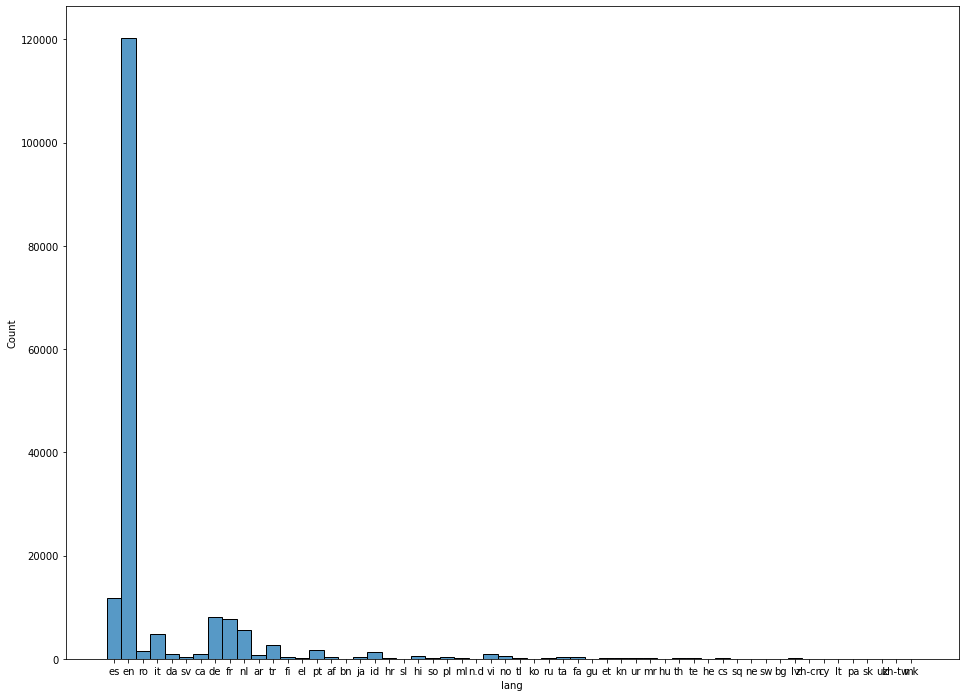

In [ ]:
# insight about the language people tweet in

lang_stat(df_elec)

In [ ]:
df_elec_en = df_elec[df_elec['lang'] == 'en']

df_elec_en.shape

# df_elec_en = df_elec

(120349, 2)

In [ ]:
df_elec_en.head(3)

,tweet,lang
1,Watch this #60MinutesInterview. #Trump posts i...,en
6,The Moment Kamala Harris Calls Joe Biden And S...,en
7,Everyone celebrating tonight... we need to don...,en


In [ ]:
df_elec_en.drop(['lang'], axis=1, inplace=True)

/usr/local/lib/python3.8/dist-packages/pandas/core/frame.py:4906: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().drop(


In [ ]:
df_elec_en['tk_tweet'] = df_elec_en['tweet'].apply(pp_tweet)

<ipython-input-48-5dd75a9bf7ff>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_elec_en['tk_tweet'] = df_elec_en['tweet'].apply(pp_tweet)


In [ ]:
df_elec_en.head(3)

,tweet,tk_tweet
1,Watch this #60MinutesInterview. #Trump posts i...,watch post prove deal unfairly watch dodge que...
6,The Moment Kamala Harris Calls Joe Biden And S...,moment kamala harris call joe biden say celebr...
7,Everyone celebrating tonight... we need to don...,celebrate tonight need donate volunteer gotv f...


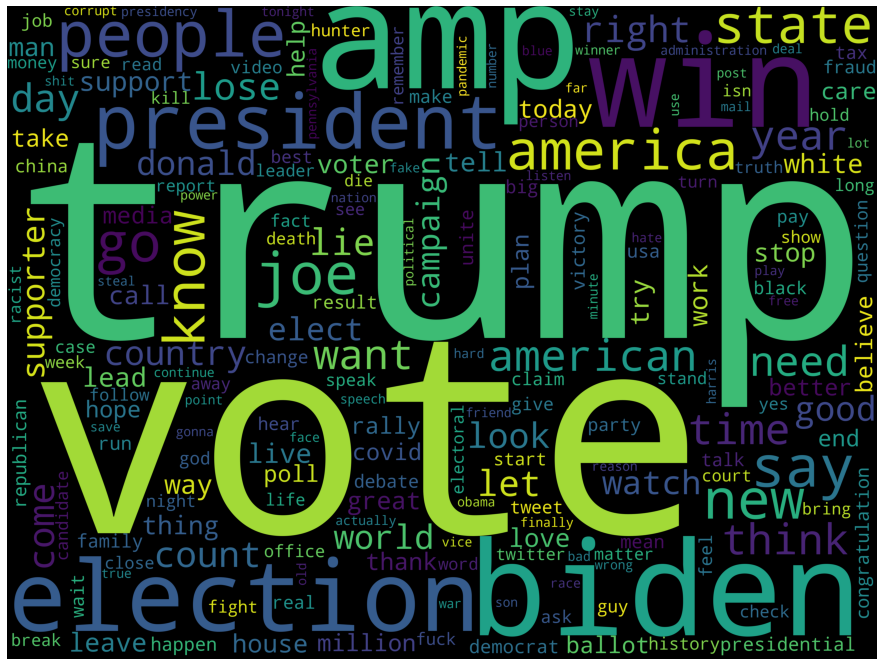

In [ ]:
gen_wordcloud(df_elec_en)

## Topic Modeling

In [ ]:
dictionary_elec, corpus_elec, lsi_elec, nmf_elec, lda_elec, \
coh_lsi_elec, coh_nmf_elec, coh_lda_elec = \
topic_modeling(df_elec_en, 2)

In [ ]:
pprint(lsi_elec.show_topics())

[(0,
  '0.522*"vote" + 0.465*"trump" + 0.306*"amp" + 0.305*"biden" + 0.250*"win" + '
  '0.174*"president" + 0.149*"election" + 0.120*"people" + 0.116*"joe" + '
  '0.099*"like"'),
 (1,
  '-0.814*"vote" + 0.415*"trump" + 0.224*"biden" + 0.209*"amp" + '
  '0.131*"president" + 0.096*"win" + -0.086*"count" + 0.086*"joe" + '
  '0.050*"donald" + 0.040*"say"')]


In [ ]:
print('LSI Coherence: ',coh_lsi_elec)

LSI Coherence:  0.4261048653855197


In [ ]:
pprint(nmf_elec.show_topics())

[(0,
  '0.060*"vote" + 0.014*"trump" + 0.011*"biden" + 0.011*"count" + 0.008*"amp" '
  '+ 0.008*"people" + 0.006*"america" + 0.006*"joe" + 0.005*"like" + '
  '0.005*"lead"'),
 (1,
  '0.066*"win" + 0.036*"election" + 0.023*"president" + 0.018*"biden" + '
  '0.016*"trump" + 0.011*"joe" + 0.009*"go" + 0.009*"state" + '
  '0.007*"congratulations" + 0.006*"presidential"')]


In [ ]:
print('NMF Coherence: ',coh_nmf_elec)

NMF Coherence:  0.44813574435635717


In [ ]:
pprint(lda_elec.show_topics())

[(0,
  '0.039*"vote" + 0.029*"trump" + 0.025*"win" + 0.022*"biden" + '
  '0.018*"election" + 0.016*"president" + 0.012*"state" + 0.010*"joe" + '
  '0.009*"like" + 0.008*"go"'),
 (1,
  '0.022*"amp" + 0.013*"people" + 0.009*"trump" + 0.007*"president" + '
  '0.007*"know" + 0.006*"lie" + 0.006*"want" + 0.006*"say" + 0.006*"like" + '
  '0.006*"country"')]


In [ ]:
print('LDA Coherence: ',coh_lda_elec)

LDA Coherence:  0.43499220521805565


In [ ]:
pyLDAvis.enable_notebook()

vis = pyLDAvis.gensim_models.prepare(lda_elec, 
                                     corpus_elec, 
                                     dictionary_elec, 
                                     mds='mmds',
                                     R=30)

vis

/usr/local/lib/python3.8/dist-packages/pyLDAvis/_prepare.py:246: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  default_term_info = default_term_info.sort_values(


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
1     -0.012165 -0.214685       1        1  53.458004
0      0.012165  0.214685       2        1  46.541996, topic_info=         Term          Freq         Total Category  logprob  loglift
98       vote  17737.000000  17737.000000  Default  30.0000  30.0000
106       win  11379.000000  11379.000000  Default  29.0000  29.0000
105  election   8389.000000   8389.000000  Default  28.0000  28.0000
442     state   5360.000000   5360.000000  Default  27.0000  27.0000
171       amp  12810.000000  12810.000000  Default  26.0000  26.0000
..        ...           ...           ...      ...      ...      ...
307     think   2624.601533   4659.133425   Topic2  -5.1629   0.1909
184   america   2607.411178   5189.842315   Topic2  -5.1695   0.0765
20        say   2410.765775   5775.929139   Topic2  -5.2479  -0.1089
300      know   2404.401846   6052.496181   Topic2  -5.2505  -0.1584
33       need   2164.339301   4139.653978   Topic2  -5.3557   0.1163

[158 rows x 6 columns], token_table=      Topic      Freq            Term
term                                 
257       1  0.999510  administration
257       2  0.000945  administration
184       1  0.497510         america
184       2  0.502327         america
321       1  0.999102        american
...     ...       ...             ...
383       2  0.016439            work
92        1  0.862502           world
92        2  0.137575           world
183       1  0.672662           years
183       2  0.327222           years

[238 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[2, 1])

# Mix two datasets

## Data Processing

In [ ]:
df_wc_en['label'] = df_wc_en['tk_tweet'].apply(lambda x: 0)

df_elec_en['label'] = df_elec_en['tk_tweet'].apply(lambda x: 1)

<ipython-input-56-9f7a02cefd47>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_wc_en['label'] = df_wc_en['tk_tweet'].apply(lambda x: 0)


NameError: ignored

In [ ]:
df = pd.concat([df_wc_en, df_elec_en], axis=0)

df = df.sample(frac=1)

df.reset_index(drop=True, inplace=True)

In [ ]:
df.to_csv('df.csv')

In [ ]:
df.head(20)

,tweet,tk_tweet,label
0,"""Argentina needs something\nMexico wants somet...",argentina need mexico want point peter drury m...,0
1,"With the #USelection just 12 days away, Presid...",days away president challenger face time nashv...,1
2,@realDonaldTrump Fixed this for you #DonaldTru...,fix,1
3,#FIFAWorldCup | #QatarWorldCup2022 |\n#Qatar20...,live stream brazil switzerland live link serve...,0
4,Who will win #WC2022 ? #QatarWorldCup2022 #Qat...,win,0
5,Can you hear the people sing! 🎶 #Biden #Michi...,hear people sing,1
6,"Jackanory, #Trump tells a story! Poor Trumpy i...",jackanory tell story poor trumpy treat badly i...,1
7,December prayer timetable - please don’t forge...,december prayer timetable forget donate ongoing,0
8,"A global cheer for Joe Biden: ""Let's go, Joe! ...",global cheer joe biden let joe let joe pass,1
9,"I lost My healthcare, too! #BidenLies #BidenCo...",lose healthcare want,1


In [ ]:
df.shape

(241099, 3)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241099 entries, 0 to 241098
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   tweet     241099 non-null  object
 1   tk_tweet  241099 non-null  object
 2   label     241099 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 5.5+ MB


In [ ]:
df.isna().sum()

tweet       0
tk_tweet    0
label       0
dtype: int64

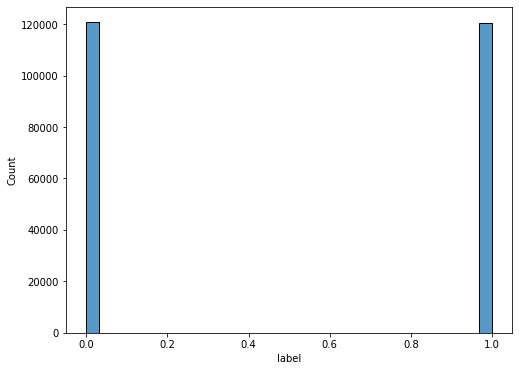

In [ ]:
fig, ax = plt.subplots(figsize=(8,6))
sns.histplot(data=df, x='label', ax = ax)

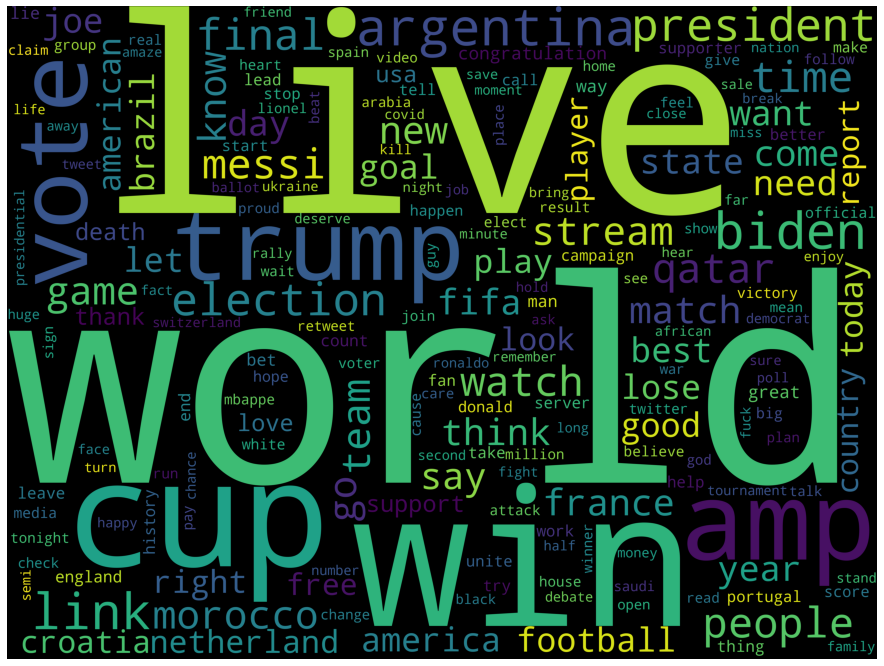

In [ ]:
gen_wordcloud(df)

## Topic Modeling

In [ ]:
dictionary, corpus, lsi, nmf, lda, \
coh_lsi, coh_nmf, coh_lda = \
topic_modeling(df, 2)

In [ ]:
df['nmf'] = set_nmf_label(df)

df['lda'] = set_lda_label(df)

df.head(50)

,tweet,tk_tweet,label,nmf,lda
0,"""Argentina needs something\nMexico wants somet...",argentina need mexico want point peter drury m...,0,0.0,0
1,"With the #USelection just 12 days away, Presid...",days away president challenger face time nashv...,1,1.0,1
2,@realDonaldTrump Fixed this for you #DonaldTru...,fix,1,1.0,1
3,#FIFAWorldCup | #QatarWorldCup2022 |\n#Qatar20...,live stream brazil switzerland live link serve...,0,0.0,0
4,Who will win #WC2022 ? #QatarWorldCup2022 #Qat...,win,0,1.0,0
5,Can you hear the people sing! 🎶 #Biden #Michi...,hear people sing,1,1.0,1
6,"Jackanory, #Trump tells a story! Poor Trumpy i...",jackanory tell story poor trumpy treat badly i...,1,1.0,1
7,December prayer timetable - please don’t forge...,december prayer timetable forget donate ongoing,0,1.0,1
8,"A global cheer for Joe Biden: ""Let's go, Joe! ...",global cheer joe biden let joe let joe pass,1,1.0,1
9,"I lost My healthcare, too! #BidenLies #BidenCo...",lose healthcare want,1,1.0,1


### LSI

In [ ]:
pprint(lsi.show_topics())

[(0,
  '0.723*"live" + 0.408*"link" + 0.247*"world" + 0.241*"stream" + 0.218*"cup" '
  '+ 0.191*"argentina" + 0.113*"netherlands" + 0.108*"watch" + 0.088*"brazil" '
  '+ 0.086*"fifa"'),
 (1,
  '0.453*"world" + 0.371*"cup" + -0.315*"live" + 0.310*"win" + 0.295*"amp" + '
  '0.244*"vote" + 0.213*"trump" + -0.182*"link" + 0.143*"biden" + '
  '0.106*"qatar"')]


In [ ]:
print('LSI Coherence: ',coh_lsi)

LSI Coherence:  0.40191049113040167


### NMF

In [ ]:
pprint(nmf.show_topics())

[(0,
  '0.027*"win" + 0.017*"world" + 0.016*"cup" + 0.012*"vote" + 0.009*"trump" + '
  '0.008*"biden" + 0.007*"morocco" + 0.007*"final" + 0.007*"argentina" + '
  '0.007*"france"'),
 (1,
  '0.166*"live" + 0.120*"link" + 0.073*"stream" + 0.046*"netherlands" + '
  '0.043*"argentina" + 0.036*"brazil" + 0.027*"watch" + 0.023*"server" + '
  '0.022*"croatia" + 0.019*"switzerland"')]


In [ ]:
print('NMF Coherence: ',coh_nmf)

NMF Coherence:  0.4727481070126826


In [ ]:
print(f"NMF accuracy: {get_tm_acc(df, df['nmf'])}")

NMF accuracy: 0.6076549467231304


In [ ]:
df.isna().sum()

tweet          0
tk_tweet       0
label          0
nmf         9286
lda            0
dtype: int64

### LDA

In [ ]:
pprint(lda.show_topics())

[(0,
  '0.039*"world" + 0.033*"live" + 0.030*"cup" + 0.018*"argentina" + '
  '0.017*"link" + 0.014*"win" + 0.014*"qatar" + 0.013*"watch" + 0.013*"team" + '
  '0.012*"game"'),
 (1,
  '0.015*"trump" + 0.014*"amp" + 0.014*"vote" + 0.010*"biden" + 0.010*"win" + '
  '0.009*"president" + 0.008*"people" + 0.007*"election" + 0.007*"know" + '
  '0.006*"like"')]


In [ ]:
print('LDA Coherence: ',coh_lda)

LDA Coherence:  0.5744968337219077


In [ ]:
print(f"LDA accuracy: {get_tm_acc(df, df['lda'])}")

LDA accuracy: 0.8236409109950684


In [ ]:
# Show the classification report

print(classification_report(df['label'], df['lda']))

              precision    recall  f1-score   support

           0       0.93      0.70      0.80    120750
           1       0.76      0.95      0.84    120349

    accuracy                           0.82    241099
   macro avg       0.85      0.82      0.82    241099
weighted avg       0.85      0.82      0.82    241099



In [ ]:
pyLDAvis.enable_notebook()

vis = pyLDAvis.gensim_models.prepare(lda, 
                                     corpus, 
                                     dictionary, 
                                     mds='mmds',
                                     R=30)

vis

/usr/local/lib/python3.8/dist-packages/pyLDAvis/_prepare.py:246: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  default_term_info = default_term_info.sort_values(


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
1     -0.014504 -0.255972       1        1  62.836481
0      0.014504  0.255972       2        1  37.163519, topic_info=          Term          Freq         Total Category  logprob  loglift
106      world  27712.000000  27712.000000  Default  30.0000  30.0000
14        live  23582.000000  23582.000000  Default  29.0000  29.0000
99         cup  21529.000000  21529.000000  Default  28.0000  28.0000
0    argentina  13070.000000  13070.000000  Default  27.0000  27.0000
25        link  12333.000000  12333.000000  Default  26.0000  26.0000
..         ...           ...           ...      ...      ...      ...
29         win  10253.675923  21985.977671   Topic2  -4.2482   0.2271
857        usa   3488.989986   4394.158738   Topic2  -5.3262   0.7592
21        time   4625.446655   9796.920927   Topic2  -5.0442   0.2393
162      today   3559.094088   5466.203923   Topic2  -5.3063   0.5608
64        like   3759.914235  11570.363816   Topic2  -5.2514  -0.1342

[115 rows x 6 columns], token_table=      Topic      Freq       Term
term                            
292       1  0.999971    america
292       2  0.000193    america
623       1  0.999879   american
623       2  0.000325   american
936       1  0.999605  americans
...     ...       ...        ...
324       2  0.000307       work
106       1  0.000036      world
106       2  0.999973      world
388       1  0.999505      years
388       2  0.000484      years

[164 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[2, 1])

In [ ]:
df.head(10)

,tweet,tk_tweet,label,nmf,lda
0,"""Argentina needs something\nMexico wants somet...",argentina need mexico want point peter drury m...,0,0.0,0
1,"With the #USelection just 12 days away, Presid...",days away president challenger face time nashv...,1,1.0,1
2,@realDonaldTrump Fixed this for you #DonaldTru...,fix,1,1.0,1
3,#FIFAWorldCup | #QatarWorldCup2022 |\n#Qatar20...,live stream brazil switzerland live link serve...,0,0.0,0
4,Who will win #WC2022 ? #QatarWorldCup2022 #Qat...,win,0,1.0,0
5,Can you hear the people sing! 🎶 #Biden #Michi...,hear people sing,1,1.0,1
6,"Jackanory, #Trump tells a story! Poor Trumpy i...",jackanory tell story poor trumpy treat badly i...,1,1.0,1
7,December prayer timetable - please don’t forge...,december prayer timetable forget donate ongoing,0,1.0,1
8,"A global cheer for Joe Biden: ""Let's go, Joe! ...",global cheer joe biden let joe let joe pass,1,1.0,1
9,"I lost My healthcare, too! #BidenLies #BidenCo...",lose healthcare want,1,1.0,1


## Sentiment Analysis

### TextBlob

In [ ]:
from textblob import TextBlob

In [ ]:
df['TextBlob'] = [TextBlob(t).polarity for t in df['tk_tweet']]

In [ ]:
df.head(10)

,tweet,tk_tweet,label,nmf,lda,TextBlob
0,"""Argentina needs something\nMexico wants somet...",argentina need mexico want point peter drury m...,0,0.0,0,0.000000
1,"With the #USelection just 12 days away, Presid...",days away president challenger face time nashv...,1,1.0,1,0.045455
2,@realDonaldTrump Fixed this for you #DonaldTru...,fix,1,1.0,1,0.000000
3,#FIFAWorldCup | #QatarWorldCup2022 |\n#Qatar20...,live stream brazil switzerland live link serve...,0,0.0,0,0.136364
4,Who will win #WC2022 ? #QatarWorldCup2022 #Qat...,win,0,1.0,0,0.800000
5,Can you hear the people sing! 🎶 #Biden #Michi...,hear people sing,1,1.0,1,0.000000
6,"Jackanory, #Trump tells a story! Poor Trumpy i...",jackanory tell story poor trumpy treat badly i...,1,1.0,1,-0.600000
7,December prayer timetable - please don’t forge...,december prayer timetable forget donate ongoing,0,1.0,1,0.000000
8,"A global cheer for Joe Biden: ""Let's go, Joe! ...",global cheer joe biden let joe let joe pass,1,1.0,1,0.000000
9,"I lost My healthcare, too! #BidenLies #BidenCo...",lose healthcare want,1,1.0,1,0.000000


### VADER

In [ ]:
vader = SentimentIntensityAnalyzer()

vader.polarity_scores(df['tk_tweet'][0])

{'neg': 0.0, 'neu': 0.526, 'pos': 0.474, 'compound': 0.6597}

In [ ]:
df['vader_compound'] = [vader.polarity_scores(t)['compound'] for t in df['tweet']]

In [ ]:
df.head(10)

,tweet,tk_tweet,label,nmf,lda,TextBlob,vader_compound
0,"""Argentina needs something\nMexico wants somet...",argentina need mexico want point peter drury m...,0,0.0,0,0.000000,0.6249
1,"With the #USelection just 12 days away, Presid...",days away president challenger face time nashv...,1,1.0,1,0.045455,0.1280
2,@realDonaldTrump Fixed this for you #DonaldTru...,fix,1,1.0,1,0.000000,0.0000
3,#FIFAWorldCup | #QatarWorldCup2022 |\n#Qatar20...,live stream brazil switzerland live link serve...,0,0.0,0,0.136364,0.0000
4,Who will win #WC2022 ? #QatarWorldCup2022 #Qat...,win,0,1.0,0,0.800000,0.5859
5,Can you hear the people sing! 🎶 #Biden #Michi...,hear people sing,1,1.0,1,0.000000,0.0000
6,"Jackanory, #Trump tells a story! Poor Trumpy i...",jackanory tell story poor trumpy treat badly i...,1,1.0,1,-0.600000,-0.9008
7,December prayer timetable - please don’t forge...,december prayer timetable forget donate ongoing,0,1.0,1,0.000000,0.1027
8,"A global cheer for Joe Biden: ""Let's go, Joe! ...",global cheer joe biden let joe let joe pass,1,1.0,1,0.000000,0.5972
9,"I lost My healthcare, too! #BidenLies #BidenCo...",lose healthcare want,1,1.0,1,0.000000,-0.4374


### Flair

In [ ]:
df['flair'] = df['tk_tweet'].apply(flair_analyser)

In [ ]:
df.head(20)

,tweet,tk_tweet,label,nmf,lda,TextBlob,vader_compound,flair
0,"""Argentina needs something\nMexico wants somet...",argentina need mexico want point peter drury m...,0,0.0,0,0.000000,0.6249,1.0
1,"With the #USelection just 12 days away, Presid...",days away president challenger face time nashv...,1,1.0,1,0.045455,0.1280,-1.0
2,@realDonaldTrump Fixed this for you #DonaldTru...,fix,1,1.0,1,0.000000,0.0000,1.0
3,#FIFAWorldCup | #QatarWorldCup2022 |\n#Qatar20...,live stream brazil switzerland live link serve...,0,0.0,0,0.136364,0.0000,1.0
4,Who will win #WC2022 ? #QatarWorldCup2022 #Qat...,win,0,1.0,0,0.800000,0.5859,1.0
5,Can you hear the people sing! 🎶 #Biden #Michi...,hear people sing,1,1.0,1,0.000000,0.0000,1.0
6,"Jackanory, #Trump tells a story! Poor Trumpy i...",jackanory tell story poor trumpy treat badly i...,1,1.0,1,-0.600000,-0.9008,-1.0
7,December prayer timetable - please don’t forge...,december prayer timetable forget donate ongoing,0,1.0,1,0.000000,0.1027,-1.0
8,"A global cheer for Joe Biden: ""Let's go, Joe! ...",global cheer joe biden let joe let joe pass,1,1.0,1,0.000000,0.5972,-1.0
9,"I lost My healthcare, too! #BidenLies #BidenCo...",lose healthcare want,1,1.0,1,0.000000,-0.4374,-1.0


In [ ]:
df.to_csv('final_df_utf32.csv')

In [ ]:
df[['nmf', 'TextBlob', 'vader_compound', 'flair']].groupby('nmf').mean()

,TextBlob,vader_compound,flair
nmf,,,
0.0,0.129152,0.211199,0.210157
1.0,0.107029,0.088185,-0.024831


In [ ]:
df[['lda', 'TextBlob', 'vader_compound', 'flair']].groupby('lda').mean()

,TextBlob,vader_compound,flair
lda,,,
0,0.159303,0.244832,0.410825
1,0.077768,0.037722,-0.200950
